In [1]:
# Jika modul belum ada, jalankan sekali:
# %pip install torch torchvision numpy pandas matplotlib scikit-image

from pathlib import Path
import random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import ConcatDataset, Subset, DataLoader
from torchvision import datasets, transforms
from skimage.metrics import structural_similarity as ssim

SEED, BATCH, LATENT = 42, 128, 64
CLASSIFIER_EPOCHS, DECODER_EPOCHS, AE_EPOCHS = 20, 15, 15
LR = 1e-3
OUT = Path('outputs/mlp_experiment'); OUT.mkdir(parents=True, exist_ok=True)
AE_PATH = Path('outputs/vanilla_ae/best_vanilla_ae.pt')
SPLIT_FILE = Path('fashion_mnist_split_seed42.npz')

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else
                      'mps' if torch.backends.mps.is_available() else 'cpu')
print('Device:', device)


Device: cuda


In [2]:
full = ConcatDataset([
    datasets.FashionMNIST('data', train=True, download=True, transform=transforms.ToTensor()),
    datasets.FashionMNIST('data', train=False, download=True, transform=transforms.ToTensor()),
])
if SPLIT_FILE.exists():
    with np.load(SPLIT_FILE) as s:
        train_idx, val_idx, test_idx = s['train_idx'], s['val_idx'], s['test_idx']
else:
    idx = torch.randperm(len(full), generator=torch.Generator().manual_seed(SEED)).numpy()
    train_idx, val_idx, test_idx = idx[:56000], idx[56000:63000], idx[63000:]
    np.savez_compressed(SPLIT_FILE, train_idx=train_idx, val_idx=val_idx, test_idx=test_idx)

assert (len(train_idx), len(val_idx), len(test_idx)) == (56000, 7000, 7000)
assert len(np.unique(np.r_[train_idx, val_idx, test_idx])) == len(full)
train_set, val_set, test_set = [Subset(full, idx.tolist()) for idx in
                                (train_idx, val_idx, test_idx)]
train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_set, batch_size=BATCH, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH, shuffle=False)
print('Train / Val / Test:', len(train_set), len(val_set), len(test_set))


100%|██████████| 26.4M/26.4M [00:02<00:00, 12.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 204kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.80MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.90MB/s]

Train / Val / Test: 56000 7000 7000


In [3]:
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, LATENT)
        self.fc3 = nn.Linear(LATENT, 10)

    def features(self, x):
        h = F.relu(self.fc1(x.flatten(1)))
        return F.relu(self.fc2(h))

    def forward(self, x):
        return self.fc3(self.features(x))

class FrozenDecoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(LATENT, 256), nn.ReLU(),
                                 nn.Linear(256, 784), nn.Sigmoid())

    def forward(self, z):
        return self.net(z).reshape(-1, 1, 28, 28)

class VanillaAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(),
                                     nn.Linear(256, LATENT), nn.ReLU())
        self.decoder = nn.Sequential(nn.Linear(LATENT, 256), nn.ReLU(),
                                     nn.Linear(256, 784), nn.Sigmoid())

    def forward(self, x):
        return self.decoder(self.encoder(x)).reshape(-1, 1, 28, 28)

def sync():
    if device.type == 'cuda': torch.cuda.synchronize()
    elif device.type == 'mps': torch.mps.synchronize()


In [4]:
classifier = MLPClassifier().to(device)
opt_c = torch.optim.Adam(classifier.parameters(), lr=LR)
history_c = []
best_val_acc = -1.0

for epoch in range(1, CLASSIFIER_EPOCHS + 1):
    classifier.train(); train_loss, n = 0.0, 0
    sync(); start = time.perf_counter()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        opt_c.zero_grad()
        loss = F.cross_entropy(classifier(x), y)
        loss.backward(); opt_c.step()
        train_loss += loss.item() * len(y); n += len(y)
    sync(); seconds = time.perf_counter() - start

    classifier.eval(); correct, total = 0, 0
    with torch.inference_mode():
        for x, y in val_loader:
            pred = classifier(x.to(device)).argmax(1).cpu()
            correct += (pred == y).sum().item(); total += len(y)
    val_acc = correct / total
    history_c.append({'epoch': epoch, 'train_cross_entropy': train_loss/n,
                      'val_accuracy': val_acc, 'training_time_s': seconds})
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(classifier.state_dict(), OUT/'best_mlp_classifier.pt')
    print(f'Classifier {epoch:02} | CE {train_loss/n:.4f} | Val Acc {val_acc:.2%}')

classifier.load_state_dict(torch.load(OUT/'best_mlp_classifier.pt', map_location=device, weights_only=True))
classifier.eval()
correct = 0
with torch.inference_mode():
    for x, y in test_loader:
        correct += (classifier(x.to(device)).argmax(1).cpu() == y).sum().item()
test_acc = correct / len(test_set)
print(f'Classifier test accuracy: {test_acc:.2%} | Target PDF ≥ 88%')
if test_acc < 0.88:
    print('PERINGATAN: belum memenuhi target 88%. Tambah CLASSIFIER_EPOCHS / tuning dan jalankan ulang.')

# Fitur z_MLP berasal dari output ReLU lapisan 64, sebelum klasifikasi akhir.
for p in classifier.parameters(): p.requires_grad_(False)
W1, W2, W3 = classifier.fc1.weight, classifier.fc2.weight, classifier.fc3.weight
print('W1, W2, W3:', tuple(W1.shape), tuple(W2.shape), tuple(W3.shape))


Classifier 01 | CE 0.5937 | Val Acc 83.20%
Classifier 02 | CE 0.4106 | Val Acc 85.83%
Classifier 03 | CE 0.3611 | Val Acc 86.73%
Classifier 04 | CE 0.3376 | Val Acc 86.03%
Classifier 05 | CE 0.3159 | Val Acc 87.60%
Classifier 06 | CE 0.2970 | Val Acc 87.64%
Classifier 07 | CE 0.2852 | Val Acc 88.13%
Classifier 08 | CE 0.2758 | Val Acc 87.97%
Classifier 09 | CE 0.2643 | Val Acc 88.46%
Classifier 10 | CE 0.2554 | Val Acc 88.60%
Classifier 11 | CE 0.2438 | Val Acc 88.74%
Classifier 12 | CE 0.2379 | Val Acc 88.59%
Classifier 13 | CE 0.2295 | Val Acc 88.11%
Classifier 14 | CE 0.2190 | Val Acc 89.47%
Classifier 15 | CE 0.2106 | Val Acc 89.19%
Classifier 16 | CE 0.2059 | Val Acc 89.16%
Classifier 17 | CE 0.1986 | Val Acc 88.91%
Classifier 18 | CE 0.1938 | Val Acc 89.31%
Classifier 19 | CE 0.1856 | Val Acc 89.21%
Classifier 20 | CE 0.1830 | Val Acc 88.50%
Classifier test accuracy: 88.50% | Target PDF ≥ 88%
W1, W2, W3: (256, 784) (64, 256) (10, 64)


In [5]:
@torch.no_grad()
def transpose_from_class(labels):
    one_hot = F.one_hot(labels, num_classes=10).float()  # [N, 10]
    z_hat = F.relu(one_hot @ W3)                         # [N, 64]
    h_hat = F.relu(z_hat @ W2)                           # [N, 256]
    return torch.sigmoid(h_hat @ W1).reshape(-1, 1, 28, 28)

@torch.no_grad()
def transpose_from_latent(x):
    z_mlp = classifier.features(x)                       # [N, 64]
    h_hat = F.relu(z_mlp @ W2)                           # [N, 256]
    return torch.sigmoid(h_hat @ W1).reshape(-1, 1, 28, 28)

x_demo, y_demo = next(iter(test_loader))
x_demo, y_demo = x_demo[:8].to(device), y_demo[:8].to(device)
img_class = transpose_from_class(y_demo)
img_latent = transpose_from_latent(x_demo)
print('Output tahap 2 / 3:', img_class.shape, img_latent.shape)


Output tahap 2 / 3: torch.Size([8, 1, 28, 28]) torch.Size([8, 1, 28, 28])


In [6]:
decoder = FrozenDecoder().to(device)
opt_d = torch.optim.Adam(decoder.parameters(), lr=LR)
history_d = []; best_decoder_val = float('inf')

def decoder_epoch(loader, training=False):
    decoder.train(training); errors = 0.0
    with torch.set_grad_enabled(training):
        for x, _ in loader:
            x = x.to(device)
            with torch.no_grad(): z = classifier.features(x)
            if training: opt_d.zero_grad()
            recon = decoder(z); loss = F.mse_loss(recon, x)
            if training: loss.backward(); opt_d.step()
            errors += F.mse_loss(recon.detach(), x, reduction='sum').item()
    return errors / (len(loader.dataset) * 784)

for epoch in range(1, DECODER_EPOCHS + 1):
    sync(); start = time.perf_counter()
    train_mse = decoder_epoch(train_loader, training=True)
    sync(); seconds = time.perf_counter() - start
    val_mse = decoder_epoch(val_loader)
    history_d.append({'epoch': epoch, 'train_mse': train_mse,
                      'val_mse': val_mse, 'training_time_s': seconds})
    if val_mse < best_decoder_val:
        best_decoder_val = val_mse
        torch.save(decoder.state_dict(), OUT/'best_frozen_decoder.pt')
    print(f'Decoder {epoch:02} | Train MSE {train_mse:.5f} | Val MSE {val_mse:.5f}')

decoder.load_state_dict(torch.load(OUT/'best_frozen_decoder.pt', map_location=device, weights_only=True))
decoder.eval()

ae = VanillaAE().to(device)
if AE_PATH.exists():
    ae.load_state_dict(torch.load(AE_PATH, map_location=device, weights_only=True))
    print('Loaded Vanilla AE:', AE_PATH)
else:
    print('Checkpoint Vanilla AE tidak ditemukan; training otomatis untuk baseline...')
    AE_PATH.parent.mkdir(parents=True, exist_ok=True)
    opt_ae = torch.optim.Adam(ae.parameters(), lr=LR)
    best_ae = float('inf')
    for epoch in range(1, AE_EPOCHS + 1):
        ae.train(); train_error = 0.0
        for x, _ in train_loader:
            x = x.to(device); opt_ae.zero_grad()
            loss = F.mse_loss(ae(x), x); loss.backward(); opt_ae.step()
            train_error += loss.item() * len(x)
        ae.eval(); val_error = 0.0
        with torch.inference_mode():
            for x, _ in val_loader:
                x = x.to(device)
                val_error += F.mse_loss(ae(x), x).item() * len(x)
        val_error /= len(val_set)
        if val_error < best_ae:
            best_ae = val_error
            torch.save(ae.state_dict(), AE_PATH)
        print(f'AE baseline {epoch:02} | Train {train_error/len(train_set):.5f} | Val {val_error:.5f}')
    ae.load_state_dict(torch.load(AE_PATH, map_location=device, weights_only=True))
ae.eval()


Decoder 01 | Train MSE 0.03659 | Val MSE 0.02693
Decoder 02 | Train MSE 0.02470 | Val MSE 0.02351
Decoder 03 | Train MSE 0.02233 | Val MSE 0.02187
Decoder 04 | Train MSE 0.02112 | Val MSE 0.02104
Decoder 05 | Train MSE 0.02032 | Val MSE 0.02041
Decoder 06 | Train MSE 0.01975 | Val MSE 0.01995
Decoder 07 | Train MSE 0.01930 | Val MSE 0.01949
Decoder 08 | Train MSE 0.01895 | Val MSE 0.01923
Decoder 09 | Train MSE 0.01867 | Val MSE 0.01925
Decoder 10 | Train MSE 0.01839 | Val MSE 0.01875
Decoder 11 | Train MSE 0.01819 | Val MSE 0.01854
Decoder 12 | Train MSE 0.01797 | Val MSE 0.01855
Decoder 13 | Train MSE 0.01781 | Val MSE 0.01826
Decoder 14 | Train MSE 0.01766 | Val MSE 0.01815
Decoder 15 | Train MSE 0.01750 | Val MSE 0.01803
Checkpoint Vanilla AE tidak ditemukan; training otomatis untuk baseline...
AE baseline 01 | Train 0.03410 | Val 0.01987
AE baseline 02 | Train 0.01771 | Val 0.01623
AE baseline 03 | Train 0.01516 | Val 0.01439
AE baseline 04 | Train 0.01368 | Val 0.01312
AE baselin

VanillaAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)

In [7]:
@torch.no_grad()
def evaluate_reconstruction(name, predict):
    error_sum, psnr_list, ssim_list = 0.0, [], []
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        recon = predict(x, y).clamp(0, 1)
        error_sum += F.mse_loss(recon, x, reduction='sum').item()
        mse_per_image = (recon - x).square().flatten(1).mean(1)
        psnr_list.extend((10 * torch.log10(1 / mse_per_image.clamp_min(1e-12))).cpu().tolist())
        for a, b in zip(x.cpu().numpy(), recon.cpu().numpy()):
            ssim_list.append(ssim(a[0], b[0], data_range=1.0))
    return {'model': name, 'test_mse': error_sum/(len(test_set)*784),
            'test_psnr_db': float(np.mean(psnr_list)),
            'test_ssim': float(np.mean(ssim_list))}

metrics = [
    evaluate_reconstruction('MLP class transpose', lambda x,y: transpose_from_class(y)),
    evaluate_reconstruction('MLP latent transpose', lambda x,y: transpose_from_latent(x)),
    evaluate_reconstruction('MLP frozen decoder', lambda x,y: decoder(classifier.features(x))),
    evaluate_reconstruction('Vanilla AE', lambda x,y: ae(x)),
]
metrics_df = pd.DataFrame(metrics)
metrics_df['dataset'] = 'Fashion-MNIST'; metrics_df['latent_dim'] = LATENT
metrics_df['seed'] = SEED; metrics_df['classifier_test_acc'] = test_acc
metrics_df.to_csv(OUT/'mlp_experiment_metrics.csv', index=False)
print(metrics_df[['model', 'test_mse', 'test_psnr_db', 'test_ssim']].round(4).to_string(index=False))

# Tahap 5: prior Gaussian diagonal dari fitur z_MLP test set
latent_test = []
with torch.inference_mode():
    for x, _ in test_loader:
        latent_test.append(classifier.features(x.to(device)).cpu())
latent_test = torch.cat(latent_test)
mu, sigma = latent_test.mean(0).to(device), latent_test.std(0, unbiased=False).clamp_min(1e-6).to(device)
with torch.inference_mode():
    z_rand = mu + sigma * torch.randn(8, LATENT, device=device)
    sampled_images = decoder(z_rand).cpu()
print('Random sample:', sampled_images.shape)

pd.DataFrame(history_c).to_csv(OUT/'mlp_classifier_history.csv', index=False)
pd.DataFrame(history_d).to_csv(OUT/'mlp_frozen_decoder_history.csv', index=False)
pd.DataFrame([{'model': 'MLP classifier', 'dataset': 'Fashion-MNIST', 'test_accuracy': test_acc,
               'target_accuracy': 0.88, 'meets_target': test_acc >= .88,
               'latent_dim': LATENT, 'seed': SEED,
               'train_time_per_epoch_s': np.mean([r['training_time_s'] for r in history_c])}]).to_csv(
                   OUT/'mlp_classifier_metrics.csv', index=False)


               model  test_mse  test_psnr_db  test_ssim
 MLP class transpose    0.1559        8.1549     0.0774
MLP latent transpose    0.2806        5.5684     0.0880
  MLP frozen decoder    0.0179       18.1931     0.6456
          Vanilla AE    0.0092       21.3202     0.7724
Random sample: torch.Size([8, 1, 28, 28])


## 8. Figur 3 — bukti visual + kurva training

Enam baris (8 contoh per baris): **original**, **transpose dari kelas**, **transpose dari latent**, **frozen decoder**, **Vanilla AE**, dan **prior sampling MLP**. Grafik tambahan memperlihatkan training classifier dan frozen decoder.

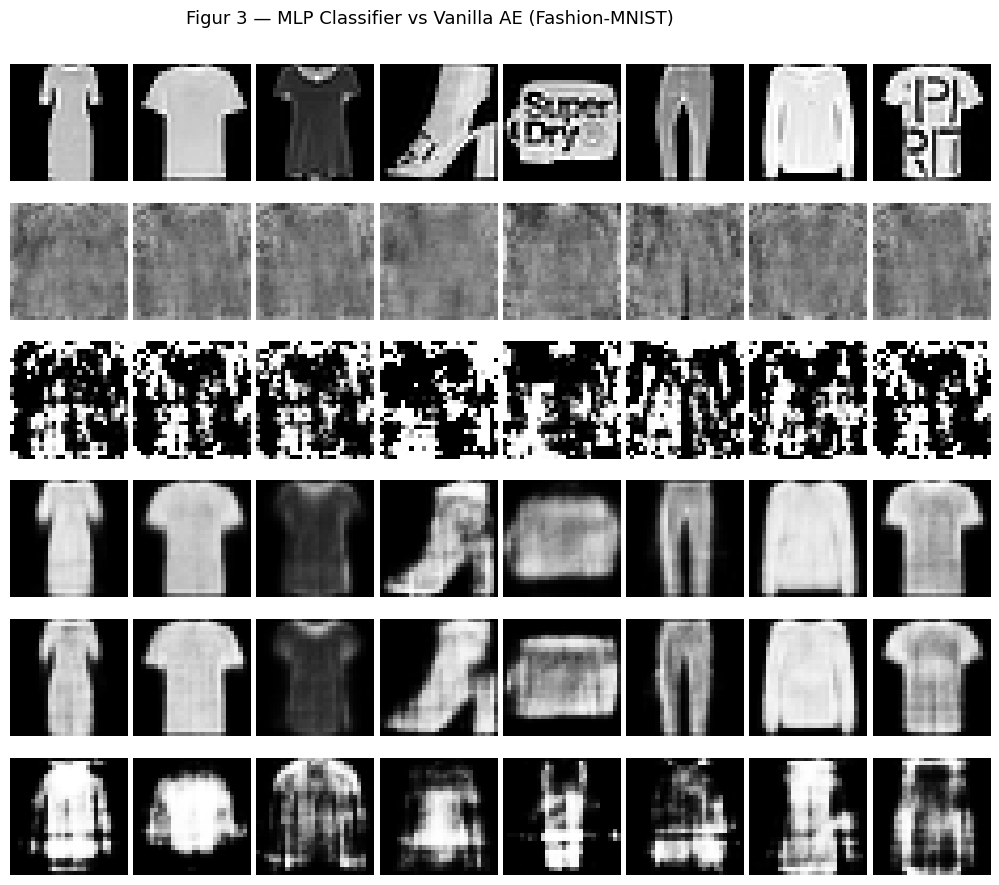

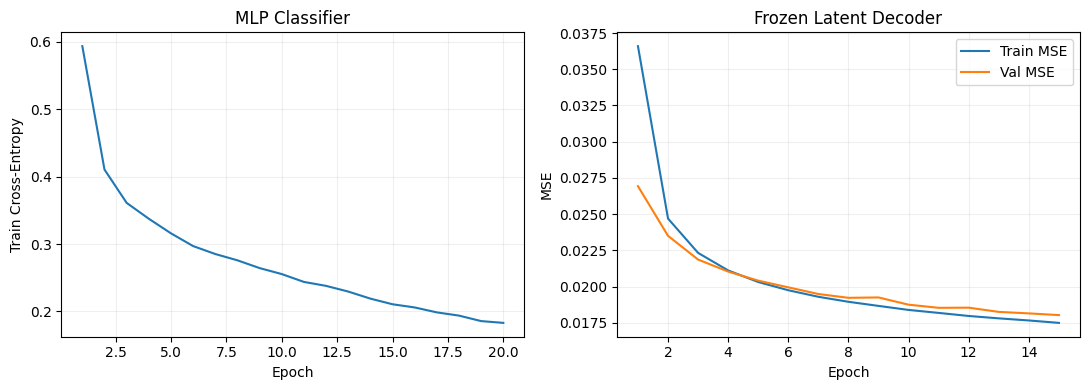

Selesai. Semua hasil: /content/outputs/mlp_experiment


In [8]:
with torch.inference_mode():
    x8, y8 = x_demo.cpu(), y_demo.cpu()
    latent_recon = decoder(classifier.features(x_demo)).cpu()
    ae_recon = ae(x_demo).cpu()

rows = [x8, img_class.cpu(), img_latent.cpu(), latent_recon, ae_recon, sampled_images]
labels = ['Original', 'Class transpose', 'Latent transpose',
          'Frozen MLP decoder', 'Vanilla AE', 'Gaussian MLP sample']
fig, axes = plt.subplots(6, 8, figsize=(14, 10))
for r in range(6):
    for i in range(8):
        axes[r, i].imshow(rows[r][i, 0], cmap='gray', vmin=0, vmax=1)
        axes[r, i].axis('off')
    axes[r, 0].set_ylabel(labels[r], rotation=0, labelpad=84, va='center', fontsize=10)
fig.suptitle('Figur 3 — MLP Classifier vs Vanilla AE (Fashion-MNIST)', fontsize=13)
fig.subplots_adjust(left=0.20, top=0.93, hspace=0.10, wspace=0.05)
fig.savefig(OUT/'figure3_mlp_experiment.png', dpi=200, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot([h['epoch'] for h in history_c], [h['train_cross_entropy'] for h in history_c])
axes[0].set(title='MLP Classifier', xlabel='Epoch', ylabel='Train Cross-Entropy')
axes[1].plot([h['epoch'] for h in history_d], [h['train_mse'] for h in history_d], label='Train MSE')
axes[1].plot([h['epoch'] for h in history_d], [h['val_mse'] for h in history_d], label='Val MSE')
axes[1].set(title='Frozen Latent Decoder', xlabel='Epoch', ylabel='MSE')
axes[1].legend()
for ax in axes: ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(OUT/'mlp_training_curves.png', dpi=200)
plt.show()
print('Selesai. Semua hasil:', OUT.resolve())


In [9]:
from google.colab import drive
drive.mount('/content/drive')
!cp -r "/content/outputs/mlp_experiment" "/content/drive/MyDrive/[CN] Colab Notebooks/[CV] Computer Vision/DCGANAE: All Experiments/Results"


Mounted at /content/drive
